# Diabetes Prediction with Machine Learning

Predict whether a patient is diabetic from eight medical measurements, using the **PIMA Indians Diabetes dataset**
(768 patients, 8 features, label `Outcome`: 0 = non-diabetic, 1 = diabetic).

**Approach:** explore the data, treat impossible zeros as missing values, compare three classifiers (linear SVM, logistic
regression, random forest) with cross-validated hyper-parameter search, and evaluate once on a held-out test set.

**Methodology note.** All preprocessing (imputation, scaling) happens *inside* a scikit-learn `Pipeline` after the
train/test split, and the model is selected with cross-validation on the training data only. This avoids data leakage, so the
test scores below are honest estimates. *(An earlier version of this project imputed missing values with per-`Outcome` medians
on the full dataset, which leaks the label into the features and inflated test accuracy to about 86%. See the README.)*

> Educational project, **not medical advice**.

# 1. Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 2
PALETTE = ['#78ffd6', '#ff9a9e']

# 2. Data collection and analysis

In [2]:
# works from the repo root, from notebooks/, or next to the file
DATA_PATH = next(p for p in ['data/diabetes.csv', '../data/diabetes.csv', 'diabetes.csv'] if os.path.exists(p))
diabetes_dataset = pd.read_csv(DATA_PATH)
diabetes_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# number of rows and columns
diabetes_dataset.shape

(768, 9)

In [4]:
# statistical measures of the data (note the minimum of 0 in columns where that is impossible)
diabetes_dataset.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
print(diabetes_dataset['Outcome'].value_counts())
print("0: Non-Diabetic\n1: Diabetic")

Outcome
0    500
1    268
Name: count, dtype: int64
0: Non-Diabetic
1: Diabetic


## Zeros that really mean "missing"

Glucose, blood pressure, skin thickness, insulin and BMI cannot physiologically be 0, so these zeros are missing measurements.
Insulin (about half the rows) and skin thickness (about a third) are affected the most.
We only mark them as `NaN` here; **the actual imputation is done later, inside the pipeline, using training data only.**

In [6]:
cols_with_invalid_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Zeros per column (before):")
print((diabetes_dataset[cols_with_invalid_zeros] == 0).sum())

diabetes_dataset[cols_with_invalid_zeros] = diabetes_dataset[cols_with_invalid_zeros].replace(0, np.nan)

print("\nMissing values (%):")
print((diabetes_dataset[cols_with_invalid_zeros].isnull().mean() * 100).round(1))

Zeros per column (before):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values (%):
Glucose           0.7
BloodPressure     4.6
SkinThickness    29.6
Insulin          48.7
BMI               1.4
dtype: float64


## Exploratory plots

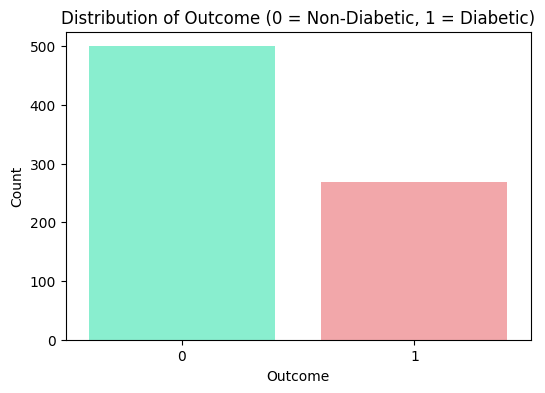

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', hue='Outcome', data=diabetes_dataset, palette=PALETTE, legend=False)
plt.title('Distribution of Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.xlabel('Outcome'); plt.ylabel('Count')
plt.show()

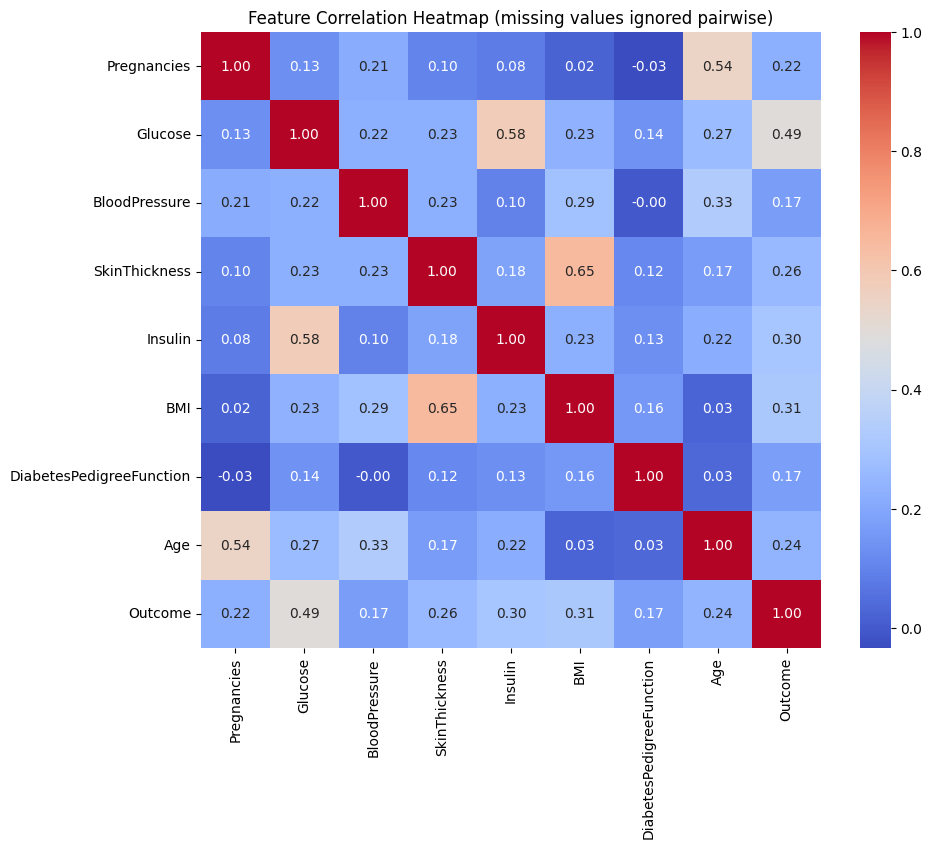

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(diabetes_dataset.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap (missing values ignored pairwise)')
plt.show()

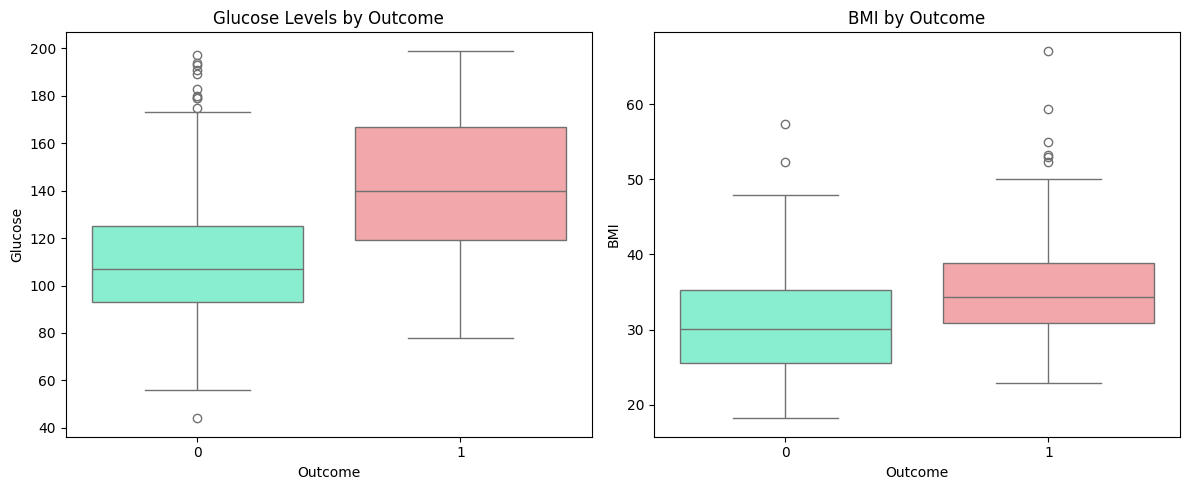

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(x='Outcome', y='Glucose', hue='Outcome', data=diabetes_dataset, ax=axes[0], palette=PALETTE, legend=False)
axes[0].set_title('Glucose Levels by Outcome')
sns.boxplot(x='Outcome', y='BMI', hue='Outcome', data=diabetes_dataset, ax=axes[1], palette=PALETTE, legend=False)
axes[1].set_title('BMI by Outcome')
plt.tight_layout(); plt.show()

In [10]:
# average of each measurement per group (missing values ignored)
diabetes_dataset.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,110.643863,70.877339,27.235457,130.287879,30.859674,0.429734,31.190000
1,4.865672,142.319549,75.321429,33.000000,206.846154,35.406767,0.550500,37.067164


# 3. Train / test split (first, before any preprocessing is learned)

Splitting before imputing or scaling guarantees the test patients never influence the preprocessing.

In [11]:
X = diabetes_dataset.drop(columns='Outcome')
Y = diabetes_dataset['Outcome']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=SEED)
print(X.shape, X_train.shape, X_test.shape)

(768, 8) (614, 8) (154, 8)


# 4. Models: pipelines with hyper-parameter search

Each model is a `Pipeline`: **median imputation -> standardization -> classifier**. `GridSearchCV` runs 5-fold cross-validation on the
training set only (the imputer and scaler are re-fitted inside every fold), optimizing **recall**, because missing a diabetic patient is
the costly mistake in a screening setting.

In [12]:
def make_pipeline(model):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler()),
                     ('model', model)])

param_grids = {
    "SVM (Linear)": {"pipeline": make_pipeline(SVC(kernel='linear')), "params": {"model__C": [0.1, 1, 10]}},
    "Logistic Regression": {"pipeline": make_pipeline(LogisticRegression(max_iter=1000)), "params": {"model__C": [0.01, 0.1, 1, 10]}},
    "Random Forest": {"pipeline": make_pipeline(RandomForestClassifier(random_state=SEED)),
                      "params": {"model__n_estimators": [50, 100, 200], "model__max_depth": [None, 5, 10]}},
}

models, results, cv_recall = {}, {}, {}

for name, config in param_grids.items():
    grid = GridSearchCV(config["pipeline"], config["params"], cv=5, scoring='recall', n_jobs=-1)
    grid.fit(X_train, Y_train)

    best_model = grid.best_estimator_
    models[name] = best_model
    cv_recall[name] = grid.best_score_

    test_pred = best_model.predict(X_test)
    results[name] = {"Accuracy": accuracy_score(Y_test, test_pred), "Precision": precision_score(Y_test, test_pred),
                     "Recall": recall_score(Y_test, test_pred), "F1 Score": f1_score(Y_test, test_pred)}

    print(f"\n--- {name} ---")
    print(f"Best Params:    {grid.best_params_}")
    print(f"Best CV Recall: {grid.best_score_:.4f}")
    print(f"Test Accuracy:  {results[name]['Accuracy']:.4f}")
    print(f"Test Precision: {results[name]['Precision']:.4f}")
    print(f"Test Recall:    {results[name]['Recall']:.4f}")
    print(f"Test F1 Score:  {results[name]['F1 Score']:.4f}")


--- SVM (Linear) ---
Best Params:    {'model__C': 0.1}
Best CV Recall: 0.5513
Test Accuracy:  0.7662
Test Precision: 0.7500
Test Recall:    0.5000
Test F1 Score:  0.6000

--- Logistic Regression ---
Best Params:    {'model__C': 1}
Best CV Recall: 0.5794
Test Accuracy:  0.7403
Test Precision: 0.6842
Test Recall:    0.4815
Test F1 Score:  0.5652



--- Random Forest ---
Best Params:    {'model__max_depth': 10, 'model__n_estimators': 100}
Best CV Recall: 0.6307
Test Accuracy:  0.7273
Test Precision: 0.6304
Test Recall:    0.5370
Test F1 Score:  0.5800


# 5. Model comparison

In [13]:
results_df = pd.DataFrame(results).T
results_df.round(3)

,Accuracy,Precision,Recall,F1 Score
SVM (Linear),0.766,0.750,0.500,0.600
Logistic Regression,0.740,0.684,0.481,0.565
Random Forest,0.727,0.630,0.537,0.580


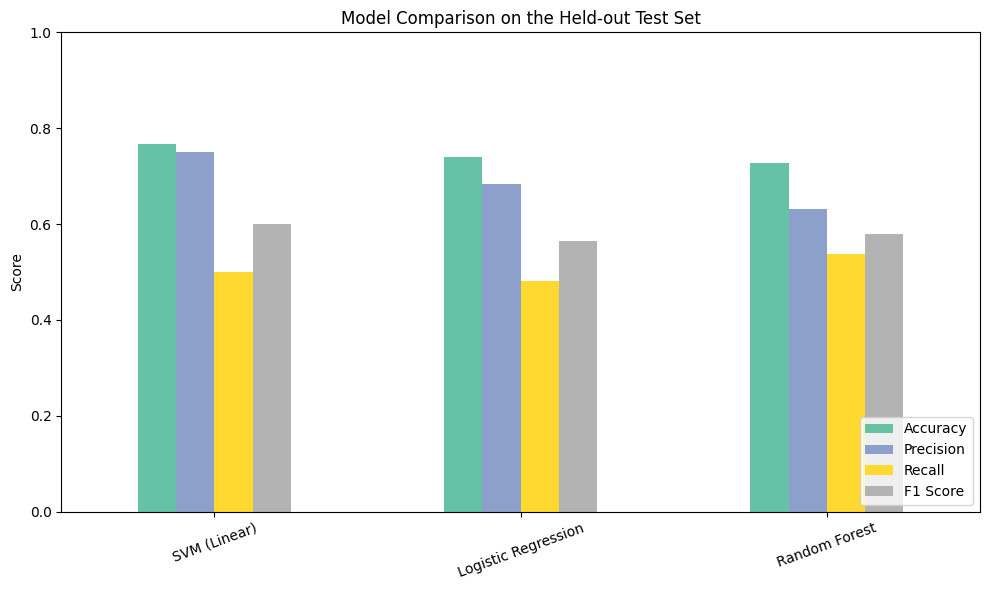

In [14]:
results_df.plot(kind='bar', figsize=(10, 6), colormap='Set2')
plt.title('Model Comparison on the Held-out Test Set')
plt.ylabel('Score'); plt.xticks(rotation=20); plt.ylim(0, 1)
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

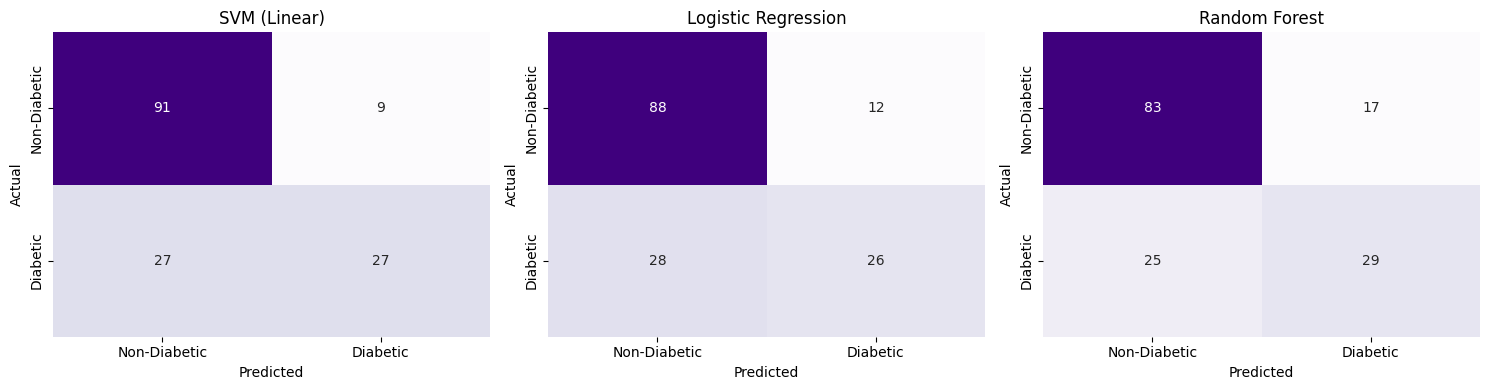

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(Y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax, cbar=False,
                xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## Which measurements matter? (Random Forest feature importance)

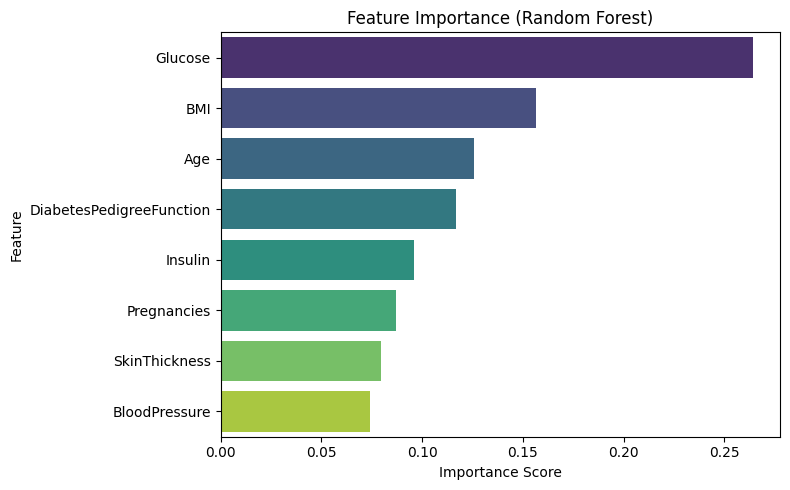

,Feature,Importance
1,Glucose,0.264
5,BMI,0.156
7,Age,0.126
6,DiabetesPedigreeFunction,0.117
4,Insulin,0.096
0,Pregnancies,0.087
3,SkinThickness,0.080
2,BloodPressure,0.074


In [16]:
rf = models["Random Forest"].named_steps['model']
feature_importance_df = (pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
                           .sort_values(by='Importance', ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_importance_df, palette='viridis', legend=False)
plt.title('Feature Importance (Random Forest)'); plt.xlabel('Importance Score')
plt.tight_layout(); plt.show()
feature_importance_df.round(3)

# 6. Model selection and evaluation

The final model is chosen by **cross-validated recall on the training set** (not by looking at the test set), then evaluated on the test set.

In [17]:
best_model_name = max(cv_recall, key=cv_recall.get)
classifier = models[best_model_name]
print(f"Selected model (highest CV recall): {best_model_name}  (CV recall = {cv_recall[best_model_name]:.3f})")

Selected model (highest CV recall): Random Forest  (CV recall = 0.631)


In [18]:
training_data_accuracy = accuracy_score(Y_train, classifier.predict(X_train))
test_data_accuracy = accuracy_score(Y_test, classifier.predict(X_test))
print('Accuracy score of the training data : ', round(training_data_accuracy, 4))
print('Accuracy score of the test data     : ', round(test_data_accuracy, 4))

Accuracy score of the training data :  0.9935
Accuracy score of the test data     :  0.7273


> The gap between training and test accuracy shows the selected model overfits (an unlimited-depth random forest memorizes the training
> rows). That is a limitation worth addressing, see the README's next steps.

# 7. Making a predictive system

The saved pipeline contains the imputer and the scaler, so you pass **raw** values. Use `NaN` (or 0 for the five columns above) for an
unknown measurement.

In [19]:
input_data = (5, 166, 72, 19, 175, 25.8, 0.587, 51)   # Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, Pedigree, Age

input_df = pd.DataFrame([input_data], columns=X.columns)
input_df[cols_with_invalid_zeros] = input_df[cols_with_invalid_zeros].replace(0, np.nan)

prediction = classifier.predict(input_df)
probability = classifier.predict_proba(input_df)[0, 1] if hasattr(classifier, 'predict_proba') else None
print(prediction)
print('The person is diabetic' if prediction[0] == 1 else 'The person is not diabetic')
if probability is not None:
    print(f'Estimated probability of diabetes: {probability:.2f}')

[1]
The person is diabetic
Estimated probability of diabetes: 0.84


In [20]:
# save into the repo's models/ folder (next to data/) no matter where the notebook is launched from
MODELS_DIR = os.path.join(os.path.dirname(os.path.dirname(DATA_PATH)), 'models')
os.makedirs(MODELS_DIR, exist_ok=True)
joblib.dump({"models": models, "best": best_model_name, "features": list(X.columns)},
            os.path.join(MODELS_DIR, 'diabetes_model.joblib'))
print("saved to", os.path.join(MODELS_DIR, 'diabetes_model.joblib'))

saved to ../models/diabetes_model.joblib


# 8. Web app

The Gradio demo lives in `app.py` (run `python app.py`). It loads this pipeline, so users can enter raw values and choose the algorithm.